In [1]:
from datetime import datetime
import os
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

In [2]:
excel_file_name = 'online_retail_II.xlsx'
project_dir = r'E:\github\c_online_retail_II'

file_path = os.path.join(project_dir, excel_file_name)
df = pd.read_excel(file_path)

In [3]:
tx_uk = df.query("Country=='United Kingdom'").reset_index(drop=True)
tx_uk['InvoiceDate'] = pd.to_datetime(tx_uk['InvoiceDate'])

In [4]:
tx_3m = tx_uk[
    (tx_uk['InvoiceDate'] >= '2010-03-01') &
    (tx_uk['InvoiceDate'] < '2010-06-01')
].reset_index(drop=True)

tx_6m = tx_uk[
    (tx_uk['InvoiceDate'] >= '2010-06-01') &
    (tx_uk['InvoiceDate'] < '2010-12-01')
].reset_index(drop=True)

In [5]:
tx_user = pd.DataFrame(tx_3m['Customer ID'].unique(), columns=['Customer ID'])

In [6]:
tx_max_purchase = tx_3m.groupby('Customer ID').InvoiceDate.max().reset_index()
tx_max_purchase.columns = ['Customer ID', 'MaxPurchaseDate']

tx_max_purchase['Recency'] = (
    tx_max_purchase['MaxPurchaseDate'].max() - tx_max_purchase['MaxPurchaseDate']
).dt.days

tx_user = tx_user.merge(
    tx_max_purchase[['Customer ID', 'Recency']],
    on='Customer ID'
)

In [7]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
tx_user['RecencyCluster'] = kmeans.fit_predict(tx_user[['Recency']])

In [8]:
def order_cluster(cluster_col, target_col, df, ascending):
    cluster_mean = df.groupby(cluster_col)[target_col].mean().sort_values(ascending=ascending)
    cluster_map = {old: new for new, old in enumerate(cluster_mean.index)}
    df[cluster_col] = df[cluster_col].map(cluster_map)
    return df

In [9]:
tx_user = order_cluster('RecencyCluster', 'Recency', tx_user, ascending=False)

In [10]:
tx_frequency = tx_3m.groupby('Customer ID').InvoiceDate.count().reset_index()
tx_frequency.columns = ['Customer ID', 'Frequency']

tx_user = tx_user.merge(tx_frequency, on='Customer ID')

In [11]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
tx_user['FrequencyCluster'] = kmeans.fit_predict(tx_user[['Frequency']])

tx_user = order_cluster('FrequencyCluster', 'Frequency', tx_user, ascending=True)

In [12]:
tx_3m['Revenue'] = tx_3m['Price'] * tx_3m['Quantity']

tx_revenue = tx_3m.groupby('Customer ID').Revenue.sum().reset_index()

tx_user = tx_user.merge(tx_revenue, on='Customer ID')

In [13]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
tx_user['RevenueCluster'] = kmeans.fit_predict(tx_user[['Revenue']])

tx_user = order_cluster('RevenueCluster', 'Revenue', tx_user, ascending=True)

In [14]:
tx_user.head()

,Customer ID,Recency,RecencyCluster,Frequency,FrequencyCluster,Revenue,RevenueCluster
0,14798.0,52,1,25,0,325.29,0
1,16717.0,2,3,38,0,673.49,0
2,16202.0,90,0,18,0,499.88,0
3,14949.0,90,0,6,0,118.68,0
4,13694.0,3,3,383,2,47272.31,3


In [15]:
tx_user['OverallScore'] = (
    tx_user['RecencyCluster'] +
    tx_user['FrequencyCluster'] +
    tx_user['RevenueCluster']
)

In [16]:
result = tx_user.groupby('OverallScore')[['Recency', 'Frequency', 'Revenue']].mean()
result

,Recency,Frequency,Revenue
OverallScore,,,
0,80.949074,17.439815,268.413333
1,61.743421,22.773026,283.337438
2,35.756148,24.569672,359.780020
3,13.761290,31.345161,513.887452
4,12.682353,80.982353,1226.162059
5,8.436975,117.075630,2558.258244
6,5.000000,254.210526,4187.758947
7,4.384615,402.615385,14614.253846
8,3.333333,893.333333,22495.623333


In [17]:
tx_user.groupby('OverallScore')['Recency'].count()

OverallScore
0    216
1    304
2    488
3    620
4    170
5    119
6     19
7     13
8      3
Name: Recency, dtype: int64

In [18]:
tx_user['Segment'] = 'Low-Value'
tx_user.loc[tx_user['OverallScore'] > 2, 'Segment'] = 'Mid-Value'
tx_user.loc[tx_user['OverallScore'] > 4, 'Segment'] = 'High-Value'

In [19]:
tx_6m['Revenue'] = tx_6m['Price'] * tx_6m['Quantity']

tx_user_6m = tx_6m.groupby('Customer ID')['Revenue'].sum().reset_index()
tx_user_6m.columns = ['Customer ID', 'm6_Revenue']

In [20]:
tx_merge = tx_user.merge(tx_user_6m, on='Customer ID', how='left')

tx_merge['m6_Revenue'] = tx_merge['m6_Revenue'].fillna(
    tx_merge['m6_Revenue'].median()
)

In [21]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
tx_merge['LTVCluster'] = kmeans.fit_predict(tx_merge[['m6_Revenue']])

tx_merge = order_cluster('LTVCluster', 'm6_Revenue', tx_merge, ascending=True)

In [22]:
tx_cluster = tx_merge.copy()
tx_cluster.head()

,Customer ID,Recency,RecencyCluster,Frequency,FrequencyCluster,Revenue,RevenueCluster,OverallScore,Segment,m6_Revenue,LTVCluster
0,14798.0,52,1,25,0,325.29,0,1,Low-Value,216.08,0
1,16717.0,2,3,38,0,673.49,0,3,Mid-Value,1693.22,0
2,16202.0,90,0,18,0,499.88,0,0,Low-Value,1014.67,0
3,14949.0,90,0,6,0,118.68,0,0,Low-Value,180.48,0
4,13694.0,3,3,383,2,47272.31,3,8,High-Value,33375.46,1


In [23]:
X = tx_merge.drop(
    ['LTVCluster', 'm6_Revenue', 'Customer ID', 'Segment'],
    axis=1,
    errors='ignore'
)

y = tx_merge['LTVCluster']

In [24]:
X = X.select_dtypes(include=['int64', 'float64'])
X = X.fillna(X.mean())

In [25]:
y = y.replace(2, 1)

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=56, stratify=y
)

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

model_rf.fit(X_train, y_train)
y_pred = model_rf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       385
           1       0.11      0.17      0.13         6

    accuracy                           0.97       391
   macro avg       0.55      0.57      0.56       391
weighted avg       0.97      0.97      0.97       391



In [28]:
import joblib
joblib.dump(model_rf, 'rf_ltv_model.pkl')

['rf_ltv_model.pkl']

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97       385
           1       0.17      0.83      0.29         6

    accuracy                           0.94       391
   macro avg       0.58      0.89      0.63       391
weighted avg       0.98      0.94      0.96       391



In [30]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

In [31]:
pipe_lr = ImbPipeline([
    ('preproc', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('clf', LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=1000))
])

pipe_lr.fit(X_train, y_train)
y_pred = pipe_lr.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97       385
           1       0.21      0.83      0.33         6

    accuracy                           0.95       391
   macro avg       0.60      0.89      0.65       391
weighted avg       0.99      0.95      0.96       391



In [32]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = ImbPipeline([
    ('preproc', preprocessor),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       385
           1       0.25      0.17      0.20         6

    accuracy                           0.98       391
   macro avg       0.62      0.58      0.59       391
weighted avg       0.98      0.98      0.98       391



In [33]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier

models = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', solver='liblinear'),
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'DecisionTree': DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

param_grids = {
    'LogisticRegression': {'clf__C': [0.1, 1, 10]},
    'RandomForest': {'clf__n_estimators': [100, 300], 'clf__max_depth': [4, 6]},
    'HistGradientBoosting': {'clf__max_iter': [100, 200], 'clf__max_depth': [3, 5]},
    'DecisionTree': {'clf__max_depth': [3, 5, 7]}
}

best_models = {}
results = {}
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = ImbPipeline([
        ('preproc', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('clf', model)
    ])

    grid = GridSearchCV(pipe, param_grids[name], cv=skf, scoring='recall_macro')
    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_
    results[name] = grid.best_score_

    print(f"{name} — Recall Macro: {grid.best_score_:.4f}")
    print(classification_report(y_test, grid.best_estimator_.predict(X_test)))

LogisticRegression — Recall Macro: 0.8545
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       385
           1       0.21      0.83      0.33         6

    accuracy                           0.95       391
   macro avg       0.60      0.89      0.65       391
weighted avg       0.99      0.95      0.96       391

RandomForest — Recall Macro: 0.8271
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       385
           1       0.29      0.67      0.40         6

    accuracy                           0.97       391
   macro avg       0.64      0.82      0.69       391
weighted avg       0.98      0.97      0.98       391

HistGradientBoosting — Recall Macro: 0.8262
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       385
           1       0.15      0.33      0.21         6

    accuracy                           0.96       391
   mac

In [34]:
best_model_name = max(results, key=results.get)
best_model = best_models[best_model_name]

print(f"Best Model: {best_model_name}")
print(f"Recall Macro: {results[best_model_name]:.4f}")

import joblib
joblib.dump(best_model, 'best_ltv_model.pkl')

Best Model: LogisticRegression
Recall Macro: 0.8545


['best_ltv_model.pkl']

In [37]:
import pandas as pd
import numpy as np

# گرفتن preprocessor فیت‌شده
fitted_preprocessor = best_model.named_steps['preproc']

# استخراج همه feature name ها به شکل امن
feature_names = fitted_preprocessor.get_feature_names_out()



In [40]:
clf = best_model.named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    fi_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': clf.feature_importances_
    }).sort_values(by='Importance', ascending=False)

    fi_df.head(15)
else:
    print("این مدل Feature Importance مستقیم ندارد.")


این مدل Feature Importance مستقیم ندارد.


In [41]:
from sklearn.linear_model import LogisticRegression

clf = best_model.named_steps['clf']

if isinstance(clf, LogisticRegression):
    fi_df = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': clf.coef_[0],
        'AbsCoefficient': np.abs(clf.coef_[0])
    }).sort_values(by='AbsCoefficient', ascending=False)

    fi_df.head(15)


In [42]:
fi_df.to_csv("feature_importance_high_value_customers.csv", index=False, encoding="utf-8-sig")


In [43]:
fi_df.head(15).to_csv(
    "top15_feature_importance_high_value_customers.csv",
    index=False,
    encoding="utf-8-sig"
)


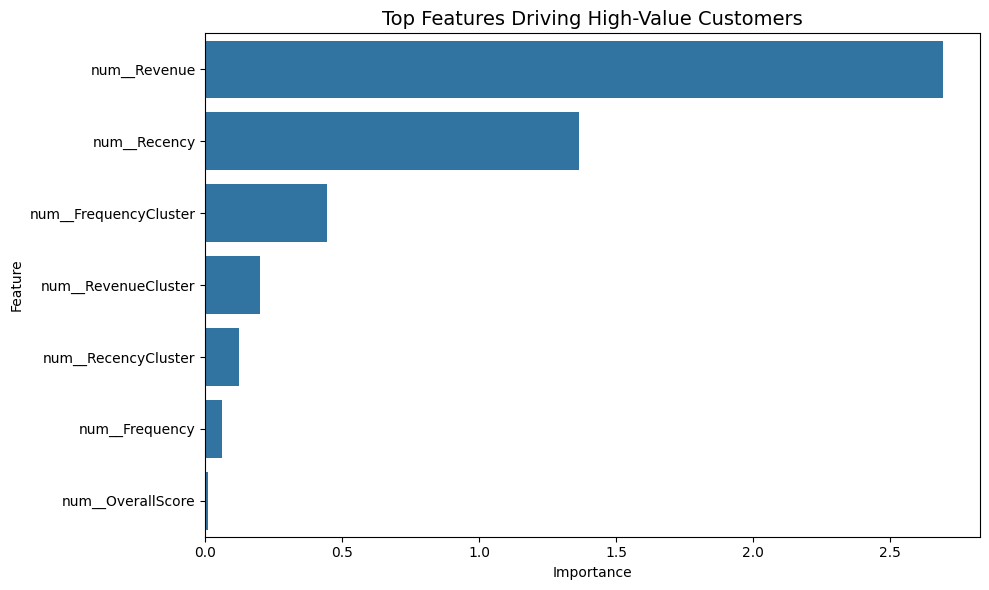

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

top_n = 15
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance" if "Importance" in fi_df.columns else "AbsCoefficient",
    y="Feature",
    data=fi_df.head(top_n)
)
plt.title("Top Features Driving High-Value Customers", fontsize=14)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [45]:
import joblib

joblib.dump(best_model, "best_pipeline_high_value_customers.pkl")


['best_pipeline_high_value_customers.pkl']

In [ ]:
loaded_model = joblib.load("best_pipeline_high_value_customers.pkl")

In [47]:
def predict_high_value_customer(customer_dict, model, threshold=0.5):
    """
    ورودی: دیکشنری ویژگی‌های یک مشتری
    خروجی: پیش‌بینی High-Value و احتمال
    """

    df = pd.DataFrame([customer_dict])

    prob = model.predict_proba(df)[0, 1]
    prediction = int(prob >= threshold)

    return {
        "HighValuePrediction": prediction,
        "Probability": round(prob, 4),
        "Threshold": threshold
    }
